# Exercise Sheet for Interpolation and Approximation
----------------------------------------------------------

In [11]:
#load some python packages you will need
import numpy as np                 #this helps compute things
import matplotlib.pyplot as plt    #this helps plot things
from scipy import interpolate

## Question 1
### a) Compute via interpolation and plot the Lagrange polynomial p(x) to $f(x) = cos(-2\pi x) + 0.4x^2$ over
### $(x_i,y_i) = [(7.2,21.04),(7.4,21.12),(7.6,22.39),(7.8,24.77]$ 


### b) Estimate the maximum absolute error bound for this Lagrange polynomial approximation over $\xi \in [x_0,x_n]$

In [78]:
x = np.arange(7,8,0.001)   #dummy range for function
y = np.cos(-2*np.pi*x) +0.4*x**2  #function f(x)


In [79]:
xi = np.array((7.2,7.4,7.6,7.8))   # points for interpolation
yi = y[np.digitize(xi, x)]
#print(xi, yi)

"""
ok... digitize returns the index for the xi, and the x here are bins
I guess, the idea is, that I do not have an analytical function,
but just two arrays
""" 
pol = interpolate.lagrange(xi, yi)
#print(pol)

#pol2 = interpolate.BarycentricInterpolator(xi, yi)

deriv_max = 16*np.pi**4/24
print ('derivative term:', deriv_max)

derivative term: 64.93939402266828


/var/folders/0v/hgyj042138z2mzg00d67ywzr0000gn/T/ipykernel_16560/3721279684.py:10: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  pol = interpolate.lagrange(xi, yi)


For the error bound we need for a lagrangian of degree n = 3
$$max_{[a,b]}\left|\frac{f^{(n)}(u)}{(n + 1)!}\right| max_{[a,b]}\left|\prod_{i=0}^n(x - x_i)\right|$$
and we need 
$$f' = 2 \pi \sin(-2\pi x) + 0.8 x, f'' = - 4 \pi^2 \cos(-2 \pi x) + 0.8, f^{(3)} = -8 \pi^3 \sin(-2\pi x), f^{(4)} = 16 \pi^4 \cos(-2\pi x)$$
4! = 24, the max of cosine = 1, so this first term evaluates to $\frac{32 \pi ^4}{24} = 64.94$

In [81]:
xab = np.linspace(7.2, 7.8, 1000)

product = np.ones_like(xab)
for x_ii in xi:
    product *= (xab - x_ii)

max_product = np.max(np.abs(product))
print('product term:', max_product)

tot_err = deriv_max * max_product
print('Total error bound:', tot_err)

# Now we compare directly
def fun(x):
    return np.cos(-2*np.pi*x) +0.4*x**2

error = np.max(np.abs(fun(xab) - pol(xab)))
print('Actual maximum error:', error)

product term: 0.0015999972642333354
Total error bound: 0.10390285277723986
Actual maximum error: 0.08499133162696637


And the product term shows a maximum of 0.0016, so the final estimated maximum error bound = 0.104.
The actual maximum error between the Lagrange polynom and the true function is 0.085, slightly lower than the error bound.

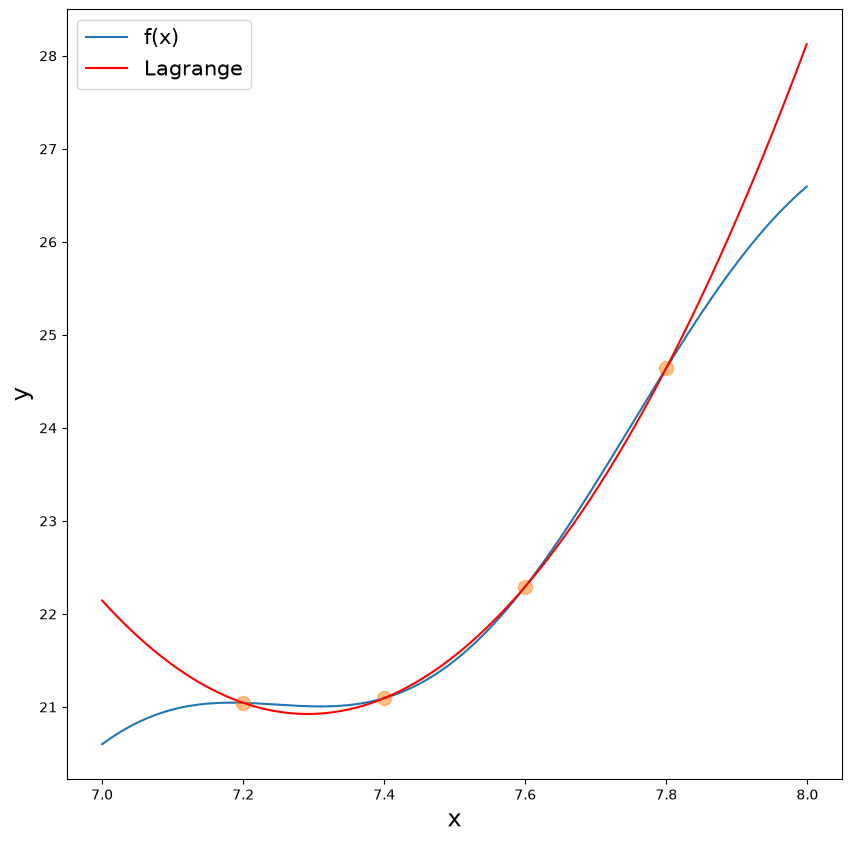

In [ ]:
plt.figure(figsize=(10,10))
plt.plot(x,y,label='f(x)')  
plt.plot(xi,yi,'o',markersize=10, alpha=0.5)
plt.plot(x, pol(x), color='red', label='Lagrange')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)
plt.legend(loc='best',fontsize=15)




----------------------------------------------------------

## Question 2
### Assume linear interpolation with step size $\textbf{d}$ is used to approximate $y(x) = \pi x^7$
### What step size for linear interpolation do you need to have for an absolute error $E_{max} < 10^{-6}$?

Regardless of the form of f(x) the error will be of the order $(x_{i+1} - x_i)^2$

----------------------------------------------------------

## Question 3
### When using Taylor polynomials to approximate $y = cos(-3 \pi x) + 3x$ over the range $x = [-0.25,0.25]$, about $x= 0$;  to what order $j$ would you need to compute the interpolating polynomial in order to keep the maximum absolute error smaller than $E_{j}(x) < 10^{-6}$?

Text(0, 0.5, 'y')

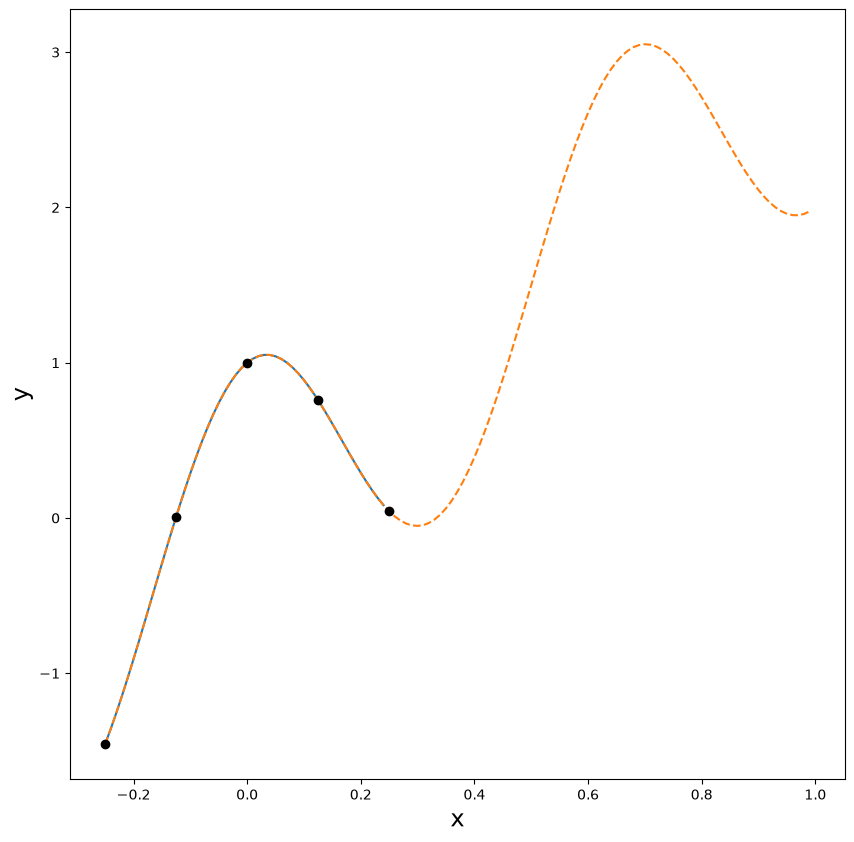

In [84]:
xi = np.arange(-0.25,1,0.01)
xdum = np.arange(-0.25,0.25,0.01)
x = np.array([-0.25,-0.125,0,0.125,0.25])
y = np.cos(-3*np.pi*x) + 3*x
ydum = np.cos(-3*np.pi*xdum) + 3*xdum
yi = np.cos(-3*np.pi*xi) + 3*xi
plt.figure(figsize=(10,10))
plt.plot(xdum,ydum)
plt.plot(xi,yi,'--')
plt.plot(x,y,'o',c='black')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)

The derivative term derived n-times is (absolute value, don't care about the (-1) factors), and alway taking the maximum of the sin/cos as 1
$$max |f'| = |3 \pi + 3|,   max |f^{n}| = (3 \pi)^n, \mathrm{for\;n > 1} $$
Below we take the formula from the lecture for Taylor series, and the maximum (x - a) = 0.25, the maximum distance of the point where we expand from the interval boundary.

In [88]:
from math import factorial, pi

x = np.linspace(-0.25, 0.25, 1000)

for j in range(100):
    E = (0.25**(j+1))/factorial(j+1)*(3 * pi)**(j+1)
    if abs(E) <= 1e-6:
        break

print(f'Need degree {j}')


Need degree 14


----------------------------------------------------------

## Question 4
## Use bilinear interpolation to determine the value of the function $f(x,y) = z$  at the point $(x_r, y_r)$, given the below four data points $x_i, y_i$ with values $z_{i} = f(x_i,y_i)$


2.0201083434056684


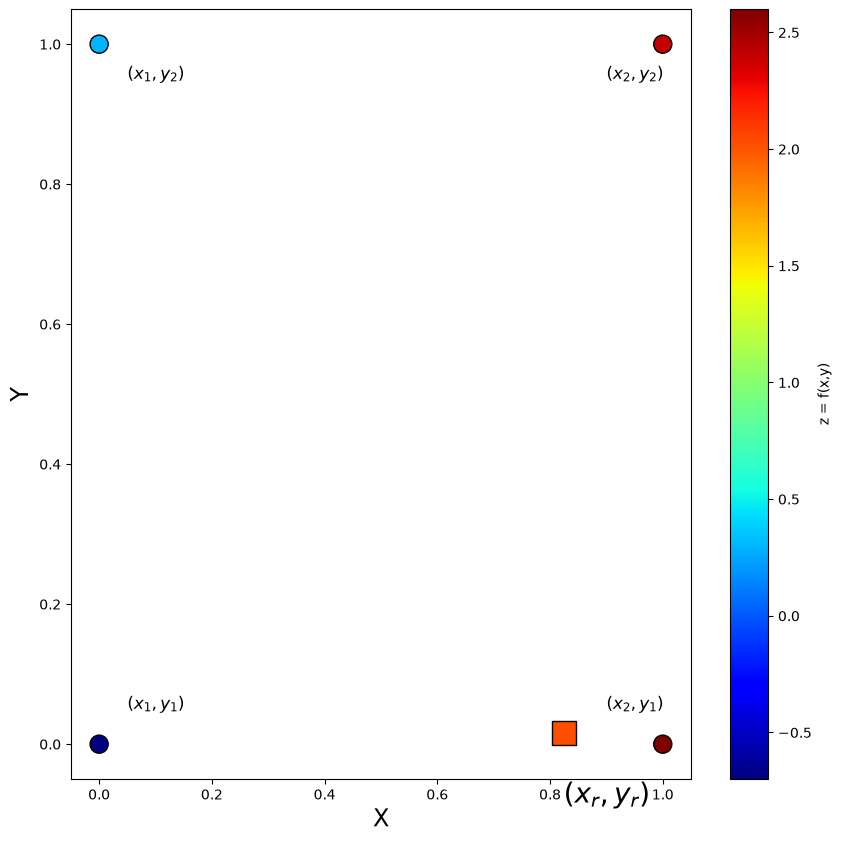

In [ ]:
#Known data points and function values.  Listed clockwise from the x_1,y_1 = (0,0) point.
xi = np.array([0,0,1,1])  #x_1,x_1,x_2,x_2
yi = np.array([0,1,1,0])  #y_1,y_2,y_2,y_1
zi = np.array([-0.7,0.3,2.4,2.6])  

#Randomly generate coordinates to find function value (z = f(x,y)) at 
xr = np.random.uniform()
yr = np.random.uniform()

# first interpolate on the left y-axis
zr_left = zi[0] + (yr - yi[0]) * (zi[1] - zi[0]) / (yi[1] - yi[0])
# then on the right y-axis
zr_right = zi[3] + (yr - yi[3]) * (zi[2] - zi[3]) / (yi[2] - yi[3])
# and now along x-axis
zr = zr_left + (xr - xi[0]) * (zr_right - zr_left) / (xi[3] - xi[0])


#Visualize
norm = plt.Normalize(vmin=zi.min(), vmax=zi.max())      # we need it, so the coloring for the two scatter calls works
plt.figure(figsize=(10,10))
plt.scatter(xi,yi,c=zi,s=170,marker='o',cmap='jet',edgecolor='black',norm=norm)
plt.scatter(xr,yr,edgecolor='black',marker='s',s=290,c=[zr], cmap='jet', norm=norm)
plt.colorbar(label='z = f(x,y)')
plt.xlabel('X',fontsize=17)
plt.ylabel('Y',fontsize=17)

plt.text(0.05,0.05,'($x_1,y_1)$',fontsize=12)
plt.text(0.05,0.95,'($x_1,y_2)$',fontsize=12)
plt.text(0.9,0.95,'($x_2,y_2)$',fontsize=12)
plt.text(0.9,0.05,'($x_2,y_1)$',fontsize=12)
plt.text(xr,yr-0.1,'($x_r,y_r)$',fontsize=20)



print(zr)
